In [1]:
import pandas as pd
import sqlalchemy
import psycopg

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


In [2]:
from getpass import getpass
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

senha = getpass("Senha do PostgreSQL: ")

url = URL.create(
    drivername="postgresql+psycopg",
    username="postgres",
    password=senha,
    host="localhost",
    port=5432,
    database="analise_vendas"
)

engine = create_engine(url, pool_pre_ping=True)

with engine.connect() as conexao:
    resultado = conexao.execute(
        text("SELECT current_database(), current_user")
    )
    print(resultado.fetchone())

del senha

('analise_vendas', 'postgres')


In [5]:

import pandas as pd
from sqlalchemy import text

try:
    with engine.connect() as conexao:
        df = pd.read_sql_query(
            text("""
                SELECT
                    v.id AS venda_id,
                    p.nome AS produto,
                    p.categoria,
                    v.quantidade,
                    p.preco AS preco_unitario,
                    v.quantidade * p.preco AS faturamento,
                    v.data_venda
                FROM public.vendas v
                INNER JOIN public.produtos p
                    ON v.produto_id = p.id
                ORDER BY v.data_venda, v.id
            """),
            conexao
        )

    print("Leitura realizada com sucesso!")
    print("Dimensões:", df.shape)
    print("Colunas:", df.columns.tolist())
    print("Tipos de dados:")
    print(df.dtypes)
    display(df.head())

except Exception as erro:
    print("Tipo do erro:", type(erro).__name__)
    print("Mensagem:", str(erro))


Leitura realizada com sucesso!
Dimensões: (12, 7)
Colunas: ['venda_id', 'produto', 'categoria', 'quantidade', 'preco_unitario', 'faturamento', 'data_venda']
Tipos de dados:
venda_id            int64
produto               str
categoria             str
quantidade          int64
preco_unitario    float64
faturamento       float64
data_venda         object
dtype: object


,venda_id,produto,categoria,quantidade,preco_unitario,faturamento,data_venda
0,3,Notebook,Computadores,2,3500.0,7000.0,2026-10-01
1,6,Mouse,Periféricos,5,80.0,400.0,2026-10-02
2,8,Teclado,Periféricos,3,150.0,450.0,2026-10-03
3,10,Monitor,Monitores,2,900.0,1800.0,2026-10-04
4,12,Headset,Áudio,4,200.0,800.0,2026-10-05


In [7]:

from decimal import Decimal

print("Quantidade de registros:", len(df))
print("Total de unidades:", df["quantidade"].sum())
print("Tipo do faturamento:", df["faturamento"].dtype)
print("Primeiros valores de faturamento:")
print(df["faturamento"].head())

total = sum(
    (Decimal(str(valor)) for valor in df["faturamento"]),
    Decimal("0")
)

print("Faturamento calculado: R$", total)


Quantidade de registros: 12
Total de unidades: 41
Tipo do faturamento: float64
Primeiros valores de faturamento:
0    7000.0
1     400.0
2     450.0
3    1800.0
4     800.0
Name: faturamento, dtype: float64
Faturamento calculado: R$ 22410.0


In [8]:

from decimal import Decimal

# Calcular os indicadores
total_registros = len(df)
total_unidades = int(df["quantidade"].sum())

faturamento = sum(
    (Decimal(str(valor)) for valor in df["faturamento"]),
    Decimal("0")
)

# Exibir o valor com duas casas decimais
print("Registros:", total_registros)
print("Unidades vendidas:", total_unidades)
print(f"Faturamento total: R$ {faturamento:,.2f}")

# Verificar os resultados
assert df.shape == (12, 7)
assert total_unidades == 41
assert faturamento == Decimal("22410.00")

print("Todas as validações passaram!")

valor_br = (
    f"{faturamento:,.2f}"
    .replace(",", "X")
    .replace(".", ",")
    .replace("X", ".")
)

print(f"Faturamento em reais: R$ {valor_br}")

Registros: 12
Unidades vendidas: 41
Faturamento total: R$ 22,410.00
Todas as validações passaram!
Faturamento em reais: R$ 22.410,00


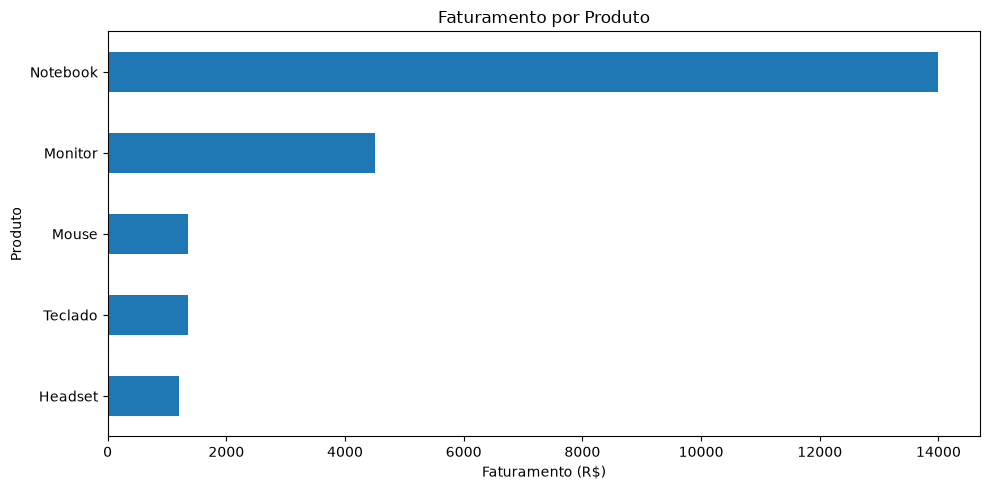

In [9]:

import matplotlib.pyplot as plt

# Agrupar e somar o faturamento por produto
faturamento_produto = (
    df.groupby("produto")["faturamento"]
    .sum()
    .sort_values(ascending=True)
)

# Criar gráfico de barras horizontais
plt.figure(figsize=(10, 5))

faturamento_produto.plot(kind="barh")

plt.title("Faturamento por Produto")
plt.xlabel("Faturamento (R$)")
plt.ylabel("Produto")
plt.tight_layout()

plt.show()


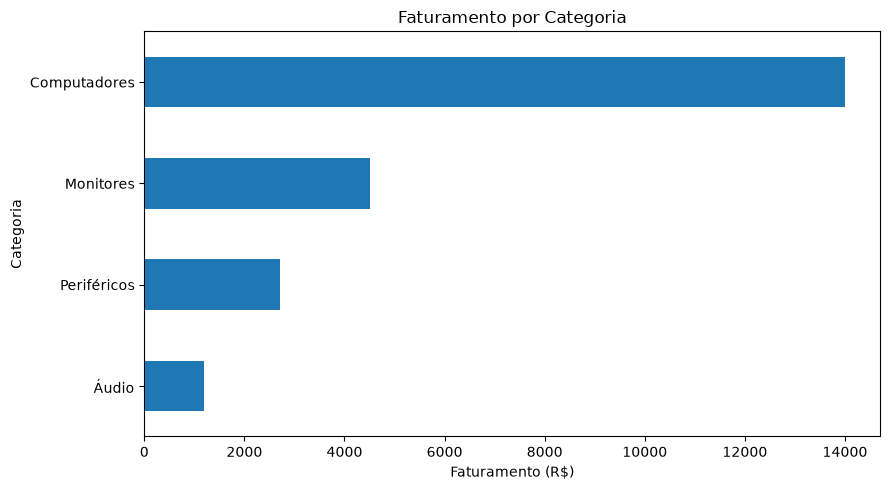

In [10]:

faturamento_categoria = (
    df.groupby("categoria")["faturamento"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(9, 5))

faturamento_categoria.plot(kind="barh")

plt.title("Faturamento por Categoria")
plt.xlabel("Faturamento (R$)")
plt.ylabel("Categoria")
plt.tight_layout()

plt.show()
